<a href="https://colab.research.google.com/github/abhinavgautam08/Cyber-Assignment-4/blob/main/2401010298.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab 4**: Explainable and Privacy-Aware AI Threat Alert
Completed solution for **ENSP355**. Source: supplied Lab Assignment 4 and simple_login_activity.csv.

The **Lab 2** trained model and settings were not supplied. This solution retrains a decision tree with `max_depth=3`, `min_samples_leaf=3`, and `random_state=42`, using a stratified 80/20 split. Missing numeric values are imputed using training-set medians. Identifiers and the target are excluded from model inputs. Results may differ from the original Lab 2 model.

In [2]:
!rm -rf /content/sample_data

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

data_path = Path('simple_login_activity.csv')
if not data_path.exists():
    from google.colab import files
    files.upload()
df = pd.read_csv(data_path)
features = ['failed_logins', 'login_hour', 'new_device', 'download_mb']
print('Rows:', len(df), '| Duplicate rows:', df.duplicated().sum())
print('Missing values:')
display(df[features + ['label']].isna().sum().to_frame('missing'))
df = df.drop_duplicates().copy()
print('Rows after removing exact duplicate records:', len(df))
assert df['label'].notna().all()
assert set(df['label']) == {'Normal', 'Suspicious'}
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=42))
])
model.fit(X_train, y_train)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Held-out accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 3))
display(pd.DataFrame(confusion_matrix(y_test, model.predict(X_test), labels=['Normal','Suspicious']),
    index=['Actual Normal','Actual Suspicious'], columns=['Predicted Normal','Predicted Suspicious']))

Saving simple_login_activity.csv to simple_login_activity.csv
Rows: 101 | Duplicate rows: 1
Missing values:


,missing
failed_logins,1
login_hour,0
new_device,0
download_mb,1
label,0


Rows after removing exact duplicate records: 100
Training rows: 80 | Test rows: 20
Held-out accuracy: 0.85


,Predicted Normal,Predicted Suspicious
Actual Normal,15,0
Actual Suspicious,3,2


## Q1. Baseline predictions with confidence (5 marks)
Confidence is the largest predicted class probability. Masking is applied before any table is displayed, including this baseline.

In [5]:
def mask_ip(ip):
    parts = str(ip).split('.')
    return f'{parts[0]}.{parts[1]}.xxx.xxx' if len(parts) == 4 else '<MASKED_IP>'

def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:] if len(text) >= 6 else '<MASKED_ACCOUNT>'

samples = pd.DataFrame([
    ['ACC-1001','192.168.10.24',0,10,0,40],
    ['ACC-1002','10.0.4.18',7,2,1,150],
    ['ACC-1003','172.16.8.90',1,15,0,720],
    ['ACC-1004','192.168.20.11',4,23,1,400],
    ['ACC-1005','10.1.1.9',2,9,0,80]
], columns=['account_id','ip_address'] + features)
samples['masked_account'] = samples['account_id'].apply(mask_account)
samples['masked_ip'] = samples['ip_address'].apply(mask_ip)
samples['prediction'] = model.predict(samples[features])
samples['confidence'] = model.predict_proba(samples[features]).max(axis=1)
baseline_table = samples[['masked_account','masked_ip'] + features + ['prediction','confidence']].copy()
display(baseline_table.round({'confidence':3}))
lowest = samples.loc[np.isclose(samples['confidence'], samples['confidence'].min())]
print('Lowest-confidence record(s):', ', '.join(lowest['masked_account']),
      '| confidence =', round(samples['confidence'].min(), 3))
print('Confidence is not certainty: leaf probabilities reflect a small training sample and may be poorly calibrated or wrong on new activity.')

,masked_account,masked_ip,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,0,10,0,40,Normal,0.932
1,ACC-***02,10.0.xxx.xxx,7,2,1,150,Suspicious,1.000
2,ACC-***03,172.16.xxx.xxx,1,15,0,720,Suspicious,0.600
3,ACC-***04,192.168.xxx.xxx,4,23,1,400,Normal,0.750
4,ACC-***05,10.1.xxx.xxx,2,9,0,80,Normal,0.932


Lowest-confidence record(s): ACC-***03 | confidence = 0.6
Confidence is not certainty: leaf probabilities reflect a small training sample and may be poorly calibrated or wrong on new activity.


## Q2. Feature importance and explanation (10 marks)

,feature,importance
0,failed_logins,0.512623
1,login_hour,0.347313
3,download_mb,0.140064
2,new_device,0.000000


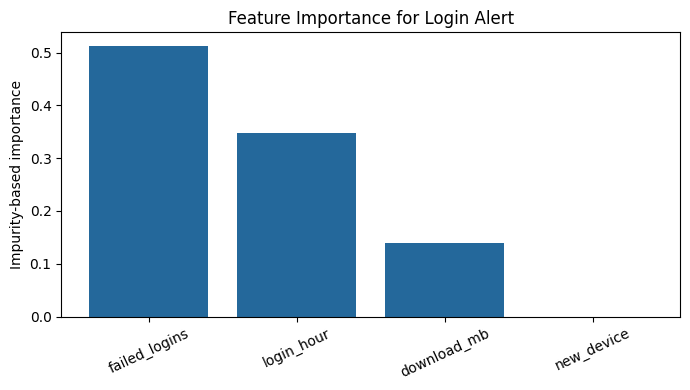

failed_logins: Repeated failed logins can indicate password guessing; the model uses this count to separate activity.
login_hour: The hour of login helps the model distinguish activity patterns, although unusual hours can be legitimate.
download_mb: Download volume helps distinguish transfer patterns; large downloads may merit verification.
Caution: importance describes global impurity reduction, not causation or a complete explanation of an individual prediction.


In [6]:
importance = pd.DataFrame({'feature':features,
    'importance':model.named_steps['tree'].feature_importances_}).sort_values('importance', ascending=False)
display(importance)
plt.figure(figsize=(7,4))
plt.bar(importance['feature'], importance['importance'], color='#24689b')
plt.title('Feature Importance for Login Alert')
plt.ylabel('Impurity-based importance')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
explanations = {
    'failed_logins':'Repeated failed logins can indicate password guessing; the model uses this count to separate activity.',
    'login_hour':'The hour of login helps the model distinguish activity patterns, although unusual hours can be legitimate.',
    'new_device':'A new device can signal unfamiliar access, although a legitimate user can also change devices.',
    'download_mb':'Download volume helps distinguish transfer patterns; large downloads may merit verification.'}
for feature in importance.head(3)['feature']:
    print(feature + ': ' + explanations[feature])
print('Caution: importance describes global impurity reduction, not causation or a complete explanation of an individual prediction.')

## Q3. Controlled sensitivity test (10 marks)

In [7]:
baseline = samples.iloc[[4]].copy()
changed = baseline.copy()
changed['failed_logins'] = 8
assert [f for f in features if baseline.iloc[0][f] != changed.iloc[0][f]] == ['failed_logins']
comparison = pd.concat([baseline[features], changed[features]], ignore_index=True)
comparison.insert(0, 'case', ['Baseline', 'Changed'])
comparison['prediction'] = model.predict(comparison[features])
comparison['confidence'] = model.predict_proba(comparison[features]).max(axis=1)
display(comparison.round({'confidence':3}))
print('Only failed_logins changed, from 2 to 8; hour, device status and download volume stayed fixed.')
print('Prediction:', comparison.iloc[0]['prediction'], 'to', comparison.iloc[1]['prediction'])
print('Confidence:', round(comparison.iloc[0]['confidence'],3), 'to', round(comparison.iloc[1]['confidence'],3))
print('A changed class shows that this perturbation crosses a learned decision boundary.' if comparison.iloc[0]['prediction'] != comparison.iloc[1]['prediction'] else 'The class is unchanged for this perturbation; this does not establish insensitivity across all inputs.')
print('This is a local model response, not proof of an attack or a causal relationship.')

,case,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,Baseline,2,9,0,80,Normal,0.932
1,Changed,8,9,0,80,Suspicious,1.000


Only failed_logins changed, from 2 to 8; hour, device status and download volume stayed fixed.
Prediction: Normal to Suspicious
Confidence: 0.932 to 1.0
A changed class shows that this perturbation crosses a learned decision boundary.
This is a local model response, not proof of an attack or a causal relationship.


## Q4. Privacy masking and responsible-use rules (5 marks)

In [8]:
display(samples[['masked_account','masked_ip','prediction','confidence']].round({'confidence':3}))
privacy_rules = [
    'Mask identifiers before every display, screenshot or export.',
    'Use sanitized or synthetic data in classroom notebooks.',
    'Restrict unmasked records to authorized personnel and retain them only as necessary.',
    'Require human review before high-risk action; do not automatically punish or block accounts.'
]
for i, rule in enumerate(privacy_rules,1):
    print(str(i) + '. ' + rule)
print('Masking reduces exposure but is not full anonymization: remaining patterns may still be linkable.')

,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,0.932
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.000
2,ACC-***03,172.16.xxx.xxx,Suspicious,0.600
3,ACC-***04,192.168.xxx.xxx,Normal,0.750
4,ACC-***05,10.1.xxx.xxx,Normal,0.932


1. Mask identifiers before every display, screenshot or export.
2. Use sanitized or synthetic data in classroom notebooks.
3. Restrict unmasked records to authorized personnel and retain them only as necessary.
4. Require human review before high-risk action; do not automatically punish or block accounts.
Masking reduces exposure but is not full anonymization: remaining patterns may still be linkable.


## Q5. Responsible alert generation (10 marks)
The following implements the supplied skeleton: Suspicious → High; otherwise confidence < 0.70 → Medium; otherwise Low. High and Medium require human review. Reasons are observable rule-based warning indicators, not extracted decision-tree paths. Several indicators alone do not escalate a Normal prediction in this skeleton; production policies would need explicit escalation rules.

In [9]:
def numeric_reason(row):
    reasons = []
    if row['failed_logins'] >= 5: reasons.append('many failed logins')
    if row['new_device'] == 1: reasons.append('new device')
    if row['login_hour'] < 6 or row['login_hour'] > 22: reasons.append('unusual login time')
    if row['download_mb'] >= 500: reasons.append('large data download')
    return ', '.join(reasons) if reasons else 'no strong warning'

def make_alert(row):
    if row['prediction'] == 'Suspicious':
        severity, action = 'High', 'Verify, contain if required, and report after human review.'
    elif row['confidence'] < 0.70:
        severity, action = 'Medium', 'Send for analyst review before action.'
    else:
        severity, action = 'Low', 'Continue normal monitoring.'
    return severity, numeric_reason(row), action, 'Yes' if severity in ['High','Medium'] else 'No'

samples[['severity','reason','recommended_action','human_review']] = pd.DataFrame(
    samples.apply(make_alert, axis=1).tolist(), index=samples.index)
final_alerts = samples[['masked_account','prediction','confidence','severity','reason','recommended_action','human_review']].copy()
display(final_alerts.round({'confidence':3}))
assert final_alerts.loc[final_alerts.severity.isin(['High','Medium']), 'human_review'].eq('Yes').all()
assert 'account_id' not in final_alerts and 'ip_address' not in final_alerts
final_alerts.to_csv('responsible_alerts.csv', index=False)
print('Limitation: a small dataset and uncalibrated tree probabilities cannot establish real-world attack likelihood. Human context and validation are needed.')

,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,0.932,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.000,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report after ...",Yes
2,ACC-***03,Suspicious,0.600,High,large data download,"Verify, contain if required, and report after ...",Yes
3,ACC-***04,Normal,0.750,Low,"new device, unusual login time",Continue normal monitoring.,No
4,ACC-***05,Normal,0.932,Low,no strong warning,Continue normal monitoring.,No


Limitation: a small dataset and uncalibrated tree probabilities cannot establish real-world attack likelihood. Human context and validation are needed.


## Conclusion
This experiment adds probability estimates, global feature importance, a controlled input change, masked reporting and explicit human review to a login classifier. The tables and chart above are the required lab evidence. No live system is accessed and no account is automatically blocked.

**Colab submission link:** open this notebook in Google Colab, run all cells with the CSV, save a copy to your Drive, then use Share → Copy link with the access required by your instructor. A hosted share link must be created from your Google account; the downloaded notebook itself is complete.
